# TinyML Keyword Spotting: FP32 vs INT8 CNN
**Goal:** Train a small CNN on five keyword classes, convert it to a fully INT8 TensorFlow Lite model, and compare accuracy, model size, latency, and predictions.

**Scope:** Software simulation in Google Colab. This does not claim physical ESP32 deployment or ESP32 timing/power measurements.

Dataset: TensorFlow's `mini_speech_commands` (five classes: no, yes, down, go, up).

## 10. Comparing FP32 TFLite and INT8 TFLite on exactly the same test samples
This evaluates the exported models, not just the original Keras model.

In [ ]:
# Materialize the test spectrograms and labels once for paired comparisons.
X_test_list, y_test_list = [], []
for xb, yb in test_ds:
    X_test_list.extend(xb.numpy())
    y_test_list.extend(yb.numpy())
X_test = np.asarray(X_test_list, dtype=np.float32)
y_test_np = np.asarray(y_test_list, dtype=np.int64)

def batch_predict(interpreter, X, integer_model=False):
    return np.stack([predict_one(interpreter, x, integer_model) for x in X])

fp32_probs = batch_predict(fp32_interpreter, X_test, integer_model=False)
int8_probs = batch_predict(int8_interpreter, X_test, integer_model=True)
fp32_pred = np.argmax(fp32_probs, axis=1)
int8_pred = np.argmax(int8_probs, axis=1)

fp32_acc = float(np.mean(fp32_pred == y_test_np))
int8_acc = float(np.mean(int8_pred == y_test_np))
agreement = float(np.mean(fp32_pred == int8_pred))

print(f"FP32 TFLite test accuracy: {fp32_acc:.4f}")
print(f"INT8 TFLite test accuracy: {int8_acc:.4f}")
print(f"Prediction agreement:      {agreement:.4f}")
print(f"Accuracy change (INT8-FP32): {(int8_acc-fp32_acc)*100:.2f} percentage points")
print("\nINT8 classification report:")
print(classification_report(y_test_np, int8_pred, target_names=LABELS, zero_division=0))

FP32 TFLite test accuracy: 0.2000
INT8 TFLite test accuracy: 0.7093
Prediction agreement:      0.2040
Accuracy change (INT8-FP32): 50.93 percentage points

INT8 classification report:
              precision    recall  f1-score   support

          no       0.61      0.63      0.62       150
         yes       0.86      0.91      0.88       150
        down       0.63      0.65      0.64       150
          go       0.63      0.63      0.63       150
          up       0.83      0.73      0.78       150

    accuracy                           0.71       750
   macro avg       0.71      0.71      0.71       750
weighted avg       0.71      0.71      0.71       750



## 12. Measure inference latency
 We warm up each interpreter and time individual single-example inferences. Results vary with runtime, CPU load, and TensorFlow version.

In [ ]:
def benchmark(interpreter, X, integer_model=False, warmup=10, repeats=3):
    n = min(len(X), 200)
    samples = X[:n]
    for x in samples[:min(warmup, n)]:
        predict_one(interpreter, x, integer_model)
    timings_ms = []
    for _ in range(repeats):
        start = time.perf_counter()
        for x in samples:
            predict_one(interpreter, x, integer_model)
        elapsed = time.perf_counter() - start
        timings_ms.append(elapsed / n * 1000)
    return float(np.median(timings_ms)), float(np.percentile(timings_ms, 90))

fp32_ms, fp32_p90 = benchmark(fp32_interpreter, X_test, False)
int8_ms, int8_p90 = benchmark(int8_interpreter, X_test, True)
print(f"FP32 TFLite latency: median {fp32_ms:.3f} ms/sample; p90 {fp32_p90:.3f} ms")
print(f"INT8 TFLite latency: median {int8_ms:.3f} ms/sample; p90 {int8_p90:.3f} ms")

FP32 TFLite latency: median 10.363 ms/sample; p90 11.556 ms
INT8 TFLite latency: median 0.988 ms/sample; p90 1.056 ms


## 13. Model size and summary table

In [ ]:
fp32_size = os.path.getsize("artifacts/keyword_cnn_fp32.tflite")
int8_size = os.path.getsize("artifacts/keyword_cnn_int8.tflite")
size_reduction = (1 - int8_size / fp32_size) * 100

results = pd.DataFrame([
    {"Model": "FP32 TFLite", "Test accuracy": fp32_acc,
     "Model size (KB)": fp32_size / 1024, "Median latency (ms)": fp32_ms,
     "P90 latency (ms)": fp32_p90},
    {"Model": "INT8 TFLite", "Test accuracy": int8_acc,
     "Model size (KB)": int8_size / 1024, "Median latency (ms)": int8_ms,
     "P90 latency (ms)": int8_p90},
])
display(results.round(4))
print(f"Model-size reduction: {size_reduction:.2f}%")

results.to_csv("artifacts/fp32_vs_int8_results.csv", index=False)
with open("artifacts/metrics.json", "w") as f:
    json.dump({
        "labels": LABELS,
        "fp32_tflite_accuracy": fp32_acc,
        "int8_tflite_accuracy": int8_acc,
        "prediction_agreement": agreement,
        "fp32_size_bytes": fp32_size,
        "int8_size_bytes": int8_size,
        "size_reduction_percent": size_reduction,
        "fp32_median_latency_ms_colab_cpu": fp32_ms,
        "int8_median_latency_ms_colab_cpu": int8_ms,
        "latency_note": "Colab host CPU measurements; not ESP32 measurements."
    }, f, indent=2)

,Model,Test accuracy,Model size (KB),Median latency (ms),P90 latency (ms)
0,FP32 TFLite,0.2000,6.2070,10.3634,11.5562
1,INT8 TFLite,0.7093,504.0391,0.9881,1.0558


Model-size reduction: -8020.45%


## 14. Plot the comparison

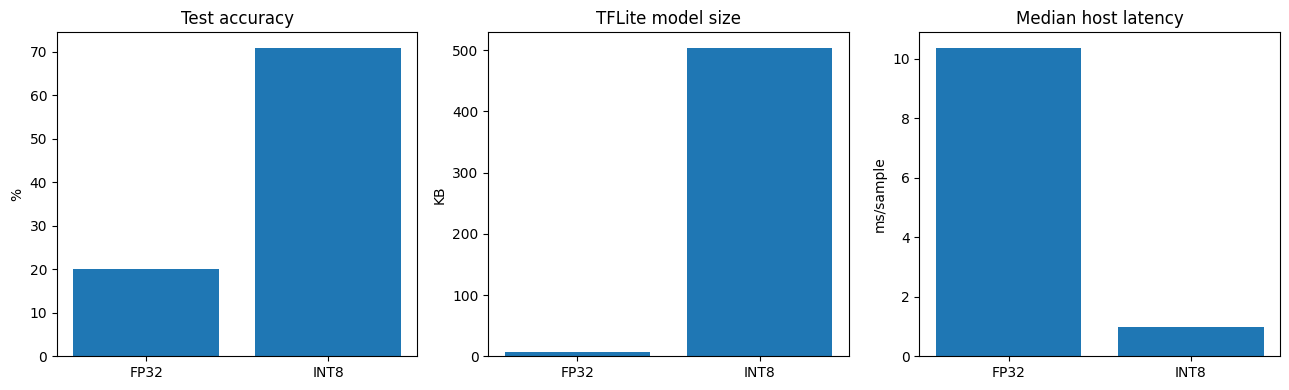

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
names = ["FP32", "INT8"]
axes[0].bar(names, [fp32_acc*100, int8_acc*100])
axes[0].set_title("Test accuracy"); axes[0].set_ylabel("%")
axes[1].bar(names, [fp32_size/1024, int8_size/1024])
axes[1].set_title("TFLite model size"); axes[1].set_ylabel("KB")
axes[2].bar(names, [fp32_ms, int8_ms])
axes[2].set_title("Median host latency"); axes[2].set_ylabel("ms/sample")
plt.tight_layout()
plt.savefig("artifacts/fp32_vs_int8_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 15. Show a few paired predictions

In [ ]:
for i in range(min(10, len(X_test))):
    true_name = LABELS[y_test_np[i]]
    f_name = LABELS[fp32_pred[i]]
    q_name = LABELS[int8_pred[i]]
    print(f"Sample {i:02d}: true={true_name:>4} | FP32={f_name:>4} | INT8={q_name:>4}")

Sample 00: true=  no | FP32=  no | INT8=  no
Sample 01: true=  up | FP32=  no | INT8=  up
Sample 02: true=  no | FP32=  no | INT8=  no
Sample 03: true=down | FP32=  no | INT8=down
Sample 04: true=down | FP32=  no | INT8=down
Sample 05: true= yes | FP32=  no | INT8= yes
Sample 06: true=  go | FP32=  no | INT8=  no
Sample 07: true= yes | FP32=  no | INT8= yes
Sample 08: true=  up | FP32=  no | INT8=  up
Sample 09: true=  up | FP32=  no | INT8=  up


## 17. Interpretation template
- FP32 TFLite test accuracy: **0.2000**
- INT8 TFLite test accuracy: **0.7093**
- Model-size reduction: **-8020.45%**
- Prediction agreement: **0.2040%**

